In [1]:
import pandas as pd

df = pd.read_csv("student_focus_dropoff_engineered.csv")

X = df.drop("drop_off", axis=1)
y = df["drop_off"]


In [2]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix , recall_score, f1_score


In [4]:
num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns
cat_cols = X_train.select_dtypes(include=["object"]).columns


In [5]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])


In [6]:
baseline_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])


In [7]:
baseline_model.fit(X_train, y_train)


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['videos_watched_14d', 'avg_watch_pct', 'avg_session_minutes',
       'login_days_14d', 'assignments_submitted', 'avg_submission_delay',
       'quiz_score_avg', 'forum_activity', 'last_active_days_ago',
       'videos_per_login', 'assignment_delay_flag', 'low_session_quality',
       'inactive_risk', 'low_quiz_score'],
      dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['quiz_score_trend'], dtype='object'))])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [8]:
y_pred = baseline_model.predict(X_test)


In [11]:


print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Recall (drop-off):", recall_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.78      0.93      0.85       742
           1       0.57      0.26      0.36       258

    accuracy                           0.76      1000
   macro avg       0.68      0.60      0.60      1000
weighted avg       0.73      0.76      0.72      1000

[[692  50]
 [191  67]]
Accuracy: 0.759
Recall (drop-off): 0.2596899224806202
F1-score: 0.35733333333333334


# Baseline Logistic Regression
#Accuracy: 76
#Recall (drop-off): X
#F1-score: X

#Dataset version: engineered_v1


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier()
}


In [13]:
from sklearn.pipeline import Pipeline


In [14]:
from sklearn.metrics import classification_report

results = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    print("\n", "="*50)
    print(name)
    print(classification_report(y_test, y_pred))

    results[name] = pipeline



Logistic Regression
              precision    recall  f1-score   support

           0       0.78      0.93      0.85       742
           1       0.57      0.26      0.36       258

    accuracy                           0.76      1000
   macro avg       0.68      0.60      0.60      1000
weighted avg       0.73      0.76      0.72      1000


Random Forest
              precision    recall  f1-score   support

           0       0.80      0.91      0.85       742
           1       0.58      0.35      0.44       258

    accuracy                           0.77      1000
   macro avg       0.69      0.63      0.65      1000
weighted avg       0.74      0.77      0.75      1000


Gradient Boosting
              precision    recall  f1-score   support

           0       0.81      0.92      0.86       742
           1       0.62      0.38      0.47       258

    accuracy                           0.78      1000
   macro avg       0.71      0.65      0.67      1000
weighted avg       

In [15]:
best_model = results["Gradient Boosting"]


In [16]:
import joblib
joblib.dump(best_model, "best_student_dropoff_model.pkl")


['best_student_dropoff_model.pkl']

In [17]:
pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", GradientBoostingClassifier())
])

In [18]:
param_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__learning_rate": [0.01, 0.05, 0.1],
    "classifier__max_depth": [3, 4, 5]
}


In [19]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


In [20]:
grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=cv,
    scoring="recall",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)


Fitting 5 folds for each of 27 candidates, totalling 135 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessing',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         Index(['videos_watched_14d', 'avg_watch_pct', 'avg_session_minutes',
       'login_days_14d', 'assignments_submitted', 'avg_submission_delay',
       'quiz_score_avg', 'forum_activity', 'last_active_d...
       'inactive_risk', 'low_quiz_score'],
      dtype='object')),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore'),
                                                                         Index(['quiz_score_trend'], dtype='object'))])),
                                       ('classifier',
                                        GradientBoostingClassifier())]),
             n_jobs=-1,
             param_grid={'classifier__learning_rate': [0.01, 0.05, 0.1],
                         'classifier__max_depth': [3, 4, 5],
                         'classifier__n_estimators': [100, 200, 300]},
             scoring='recall', verbose=1)

In [21]:
best_model = grid_search.best_estimator_
print(grid_search.best_params_)


{'classifier__learning_rate': 0.05, 'classifier__max_depth': 3, 'classifier__n_estimators': 300}


In [22]:
from sklearn.metrics import classification_report

y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.81      0.91      0.86       742
           1       0.59      0.40      0.47       258

    accuracy                           0.77      1000
   macro avg       0.70      0.65      0.67      1000
weighted avg       0.76      0.77      0.76      1000



In [23]:
import joblib
joblib.dump(best_model, "final_student_dropoff_model.pkl")


['final_student_dropoff_model.pkl']

In [24]:
import joblib

model = joblib.load("final_student_dropoff_model.pkl")

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]


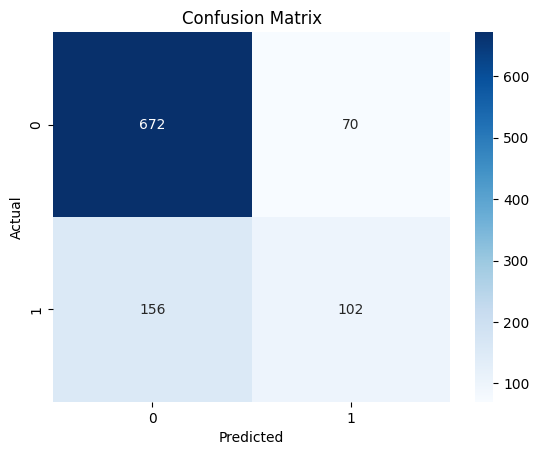

In [25]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


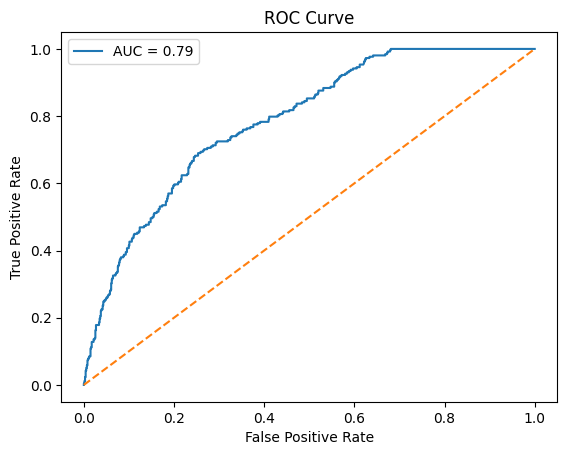

In [26]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.plot([0,1],[0,1],"--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


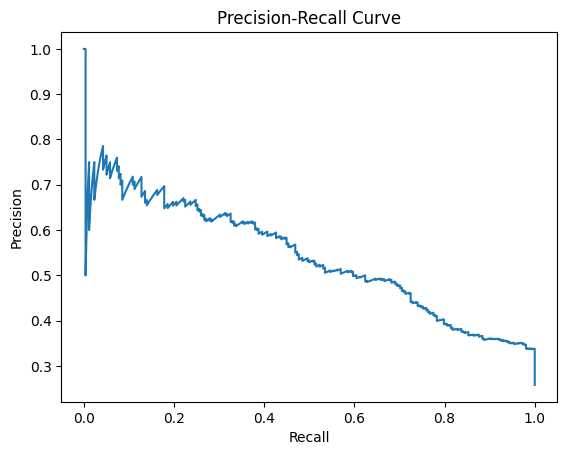

In [27]:
from sklearn.metrics import precision_recall_curve

precision, recall, _ = precision_recall_curve(y_test, y_proba)

plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.show()


In [28]:
import numpy as np

bins = np.linspace(0,1,10)
digitized = np.digitize(y_proba, bins)

for i in range(1, len(bins)):
    mask = digitized == i
    if mask.sum() > 0:
        print("Pred prob range:", bins[i-1], "-", bins[i],
              "Actual drop rate:", y_test[mask].mean())


Pred prob range: 0.0 - 0.1111111111111111 Actual drop rate: 0.01937984496124031
Pred prob range: 0.1111111111111111 - 0.2222222222222222 Actual drop rate: 0.20327868852459016
Pred prob range: 0.2222222222222222 - 0.3333333333333333 Actual drop rate: 0.2796610169491525
Pred prob range: 0.3333333333333333 - 0.4444444444444444 Actual drop rate: 0.3669724770642202
Pred prob range: 0.4444444444444444 - 0.5555555555555556 Actual drop rate: 0.463768115942029
Pred prob range: 0.5555555555555556 - 0.6666666666666666 Actual drop rate: 0.5512820512820513
Pred prob range: 0.6666666666666666 - 0.7777777777777777 Actual drop rate: 0.6511627906976745
Pred prob range: 0.7777777777777777 - 0.8888888888888888 Actual drop rate: 0.7777777777777778
Pred prob range: 0.8888888888888888 - 1.0 Actual drop rate: 0.5


In [29]:
low_login = X_test["login_days_14d"] < 4

from sklearn.metrics import recall_score

print("Recall (low login students):",
      recall_score(y_test[low_login], y_pred[low_login]))


Recall (low login students): 0.6759259259259259


In [30]:
high_score = X_test["quiz_score_avg"] > 80

print("Recall (high score students):",
      recall_score(y_test[high_score], y_pred[high_score]))


Recall (high score students): 0.44594594594594594


In [31]:
errors = X_test.copy()
errors["actual"] = y_test
errors["predicted"] = y_pred

misclassified = errors[errors["actual"] != errors["predicted"]]
misclassified.head()


,videos_watched_14d,avg_watch_pct,avg_session_minutes,login_days_14d,assignments_submitted,avg_submission_delay,quiz_score_avg,quiz_score_trend,forum_activity,last_active_days_ago,videos_per_login,assignment_delay_flag,low_session_quality,inactive_risk,low_quiz_score,actual,predicted
2145,17,30.964658,8.874491,7,3,0.797559,90.326404,improving,2,9,2.125000,0,1,1,0,1,0
2410,8,77.242507,48.516363,8,5,6.788133,81.780920,declining,2,7,0.888889,1,0,1,0,1,0
1265,5,63.012844,28.959590,4,4,2.735568,53.278927,declining,0,2,1.000000,0,0,0,0,1,0
3439,7,65.768255,35.130141,12,1,1.334338,78.117133,declining,3,2,0.538462,0,0,0,0,1,0
4002,13,79.327311,35.478142,2,2,1.488369,70.769241,declining,1,5,4.333333,0,0,0,0,0,1


In [32]:
errors = X_test.copy()
errors["actual"] = y_test
errors["predicted"] = y_pred

false_negatives = errors[(errors["actual"]==1) & (errors["predicted"]==0)]
false_positives = errors[(errors["actual"]==0) & (errors["predicted"]==1)]


In [33]:
false_negatives.describe()


,videos_watched_14d,avg_watch_pct,avg_session_minutes,login_days_14d,assignments_submitted,avg_submission_delay,quiz_score_avg,forum_activity,last_active_days_ago,videos_per_login,assignment_delay_flag,low_session_quality,inactive_risk,low_quiz_score,actual,predicted
count,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.00000,156.000000,156.000000,156.000000,156.0,156.0
mean,8.243590,62.600515,32.515397,7.314103,2.916667,2.143237,70.062928,2.102564,7.205128,1.336776,0.24359,0.032051,0.685897,0.096154,1.0,0.0
std,2.967288,20.903883,14.380228,3.806284,1.610283,2.139211,15.818723,1.405884,3.765236,1.011842,0.43063,0.176704,0.465652,0.295752,0.0,0.0
min,1.000000,10.000000,5.000000,1.000000,0.000000,0.007119,30.068825,0.000000,0.000000,0.200000,0.00000,0.000000,0.000000,0.000000,1.0,0.0
25%,6.000000,45.383219,22.580418,4.000000,2.000000,0.614366,58.845834,1.000000,4.000000,0.710714,0.00000,0.000000,0.000000,0.000000,1.0,0.0
50%,8.000000,65.559758,32.375705,7.500000,3.000000,1.531610,70.415645,2.000000,7.500000,1.000000,0.00000,0.000000,1.000000,0.000000,1.0,0.0
75%,10.000000,76.805136,42.689026,10.000000,4.000000,2.980885,81.043152,3.000000,10.000000,1.666667,0.00000,0.000000,1.000000,0.000000,1.0,0.0
max,19.000000,100.000000,85.709217,14.000000,8.000000,10.000000,100.000000,7.000000,13.000000,5.500000,1.00000,1.000000,1.000000,1.000000,1.0,0.0
